# 15 - Capillary Pressure & Saturation-Height

**Part B - Petrophys Curriculum**

Water saturation from resistivity (Archie) tells you the fluid content *at each
depth independently*. A **saturation-height model** does something different and
deeper: it predicts $S_w$ from the **rock quality (porosity, permeability)** and
the **height above the free-water level (FWL)**, grounded in the physics of
**capillary pressure**. It lets you populate $S_w$ where logs are poor, build a
consistent 3-D saturation model, and QC the resistivity-based $S_w$.

This lesson demonstrates the `petrophys.interpretation.saturation.height`
module - capillary-pressure primitives, the Leverett J-function, a fitted
J-function model, and a log-column Sw-vs-depth predictor - using the COSTA
carbonate well **HW-3**. Its LAS file covers only the **Kharaib-2 reservoir
interval**, not the whole well. HW-3 ships no laboratory $P_c$ curve, so the
J-function is fitted the field way, from core-corrected rock-quality curves and
an assumed FWL; the library's single-plug lab-curve fitter (`fit_brooks_corey`)
is referenced but not demonstrated - we do not fabricate lab data.

Section 3b adds a separate real-data FWL interpretation for **35/11-13** using
MDT formation pressures and the original report plot. Its contact is not used
as the FWL of HW-3.

## Learning goals

- Convert between **capillary pressure ($P_c$)** and **height above the FWL**,
  and understand the buoyancy that lifts hydrocarbon into the pore system.
- Normalise Pc across rock qualities with the **Leverett J-function**.
- **Fit** a J-function ($S_w = a\,J^b$) to porosity, permeability and
  saturation data, and know when the single-plug Brooks-Corey fitter applies
  instead.
- Convert a **laboratory** Pc (air-mercury) to **reservoir** conditions.
- Predict **$S_w$ versus depth from logs** with a fitted model + an FWL depth,
  and overlay it on the log-derived $S_w$.
- Fit oil/water pressure gradients using QC-selected MDT points on a TVD datum,
  and compare their intersection with a reported FWL.

## Why this matters (the physics)

Above the free-water level, buoyancy of the lighter hydrocarbon against the
denser water creates a **capillary pressure** that forces water out of the
larger pores first. In field units:

$$P_c = 0.433\,(\mathrm{SG}_w - \mathrm{SG}_{hc})\,h \quad [\text{psi}],\; h\text{ in ft}$$

so **height above the FWL is just a rescaled capillary pressure**. At a given
height, a *tight* rock (small pores, high entry pressure) holds **more** water
than a *good* rock. To compare rocks of different quality on one curve, Leverett
defined the dimensionless **J-function**:

$$J = 0.21645\,\frac{P_c}{\sigma\cos\theta}\,\sqrt{\frac{k}{\phi}}$$

which folds in each rock's $k/\phi$. Fitting $S_w = a\,J^b$ once then lets us map
**any** ($k,\phi,h$) triple to a saturation - the engine of a saturation-height
model.

### Prerequisites
Work through Part A water-saturation (07) and permeability (08) first. Knowing
Archie $S_w$ and the porosity/permeability curves will make the log overlay at
the end meaningful.

In [1]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys as pp
from petrophys.interpretation.saturation.height import (
    # capillary primitives
    pc_from_height, height_from_pc, convert_pc_lab_to_reservoir,
    leverett_j, pc_from_j, FLUID_SYSTEMS,
    # fitted models
    fit_j_function, saturation_height_from_logs,
)

print("petrophys", pp.__version__)
print("fluid systems (IFT dyne/cm, contact angle deg):")
for name, (ift, theta) in FLUID_SYSTEMS.items():
    print("  %-12s IFT=%6.1f  theta=%5.1f" % (name, ift, theta))

petrophys 3.0.0
fluid systems (IFT dyne/cm, contact angle deg):
  air_mercury  IFT= 480.0  theta=140.0
  air_brine    IFT=  72.0  theta=  0.0
  oil_brine    IFT=  30.0  theta= 30.0
  gas_brine    IFT=  50.0  theta=  0.0


## 1. Capillary pressure and height above the FWL

The `pc_from_height` / `height_from_pc` pair converts between the two using the
buoyancy gradient $0.433\,(\mathrm{SG}_w - \mathrm{SG}_{hc})$. Below we use an oil
column: water SG = 1.0, oil SG = 0.8.

In [2]:
sg_water, sg_oil = 1.0, 0.8
heights = np.array([0, 25, 50, 100, 200, 400])   # ft above FWL
pc = pc_from_height(heights, sg_water=sg_water, sg_hc=sg_oil)

tbl = pd.DataFrame({'height above FWL (ft)': heights, 'Pc (psi)': pc})
print(tbl.to_string(index=False))
print()
# round-trip check
h_back = height_from_pc(pc, sg_water=sg_water, sg_hc=sg_oil)
print('round-trip height_from_pc matches:', np.allclose(h_back, heights))
grad = 0.433 * (sg_water - sg_oil)
print('buoyancy gradient = %.4f psi/ft' % grad)

 height above FWL (ft)  Pc (psi)
                     0     0.000
                    25     2.165
                    50     4.330
                   100     8.660
                   200    17.320
                   400    34.640

round-trip height_from_pc matches: True
buoyancy gradient = 0.0866 psi/ft


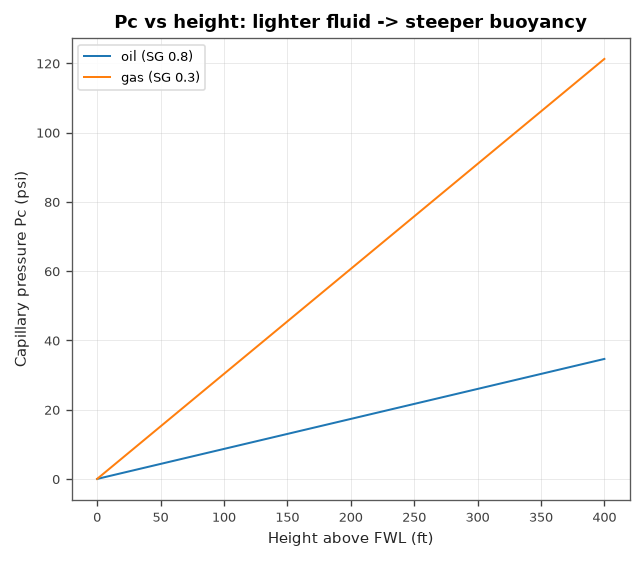

In [3]:
from petrophys.visualization import create_line_comparison

h = np.linspace(0, 400, 100)
series = {
    'oil (SG 0.8)': pc_from_height(h, sg_water, 0.8),
    'gas (SG 0.3)': pc_from_height(h, sg_water, 0.3),
}
# create_line_comparison plots each series vs a shared x; here x is HEIGHT and
# each series is the Pc it produces.
fig, ax = create_line_comparison(
    h, series,
    xlabel='Height above FWL (ft)', ylabel='Capillary pressure Pc (psi)',
    title='Pc vs height: lighter fluid -> steeper buoyancy',
    figsize=(6, 5),
)
plt.show()

Gas (lower SG) has a larger density contrast with water, so it develops the
same capillary pressure over a **shorter** height - gas columns build $P_c$
faster than oil columns.

## 2. Lab-to-reservoir Pc conversion

Core Pc is usually measured in an **air-mercury** or **air-brine** apparatus,
not at reservoir fluid conditions. The measured $P_c$ scales with the
interfacial tension and wettability of the fluid pair:

$$P_{c,res} = P_{c,lab}\,\frac{(\sigma\cos\theta)_{res}}{(\sigma\cos\theta)_{lab}}$$

`convert_pc_lab_to_reservoir` and the `FLUID_SYSTEMS` table make this a one-liner.
Air-mercury Pc is roughly an **order of magnitude** higher than the equivalent
oil-brine reservoir Pc (about 14x with the constants used here).

In [4]:
ift_lab, theta_lab = FLUID_SYSTEMS['air_mercury']   # (480, 140)
ift_res, theta_res = FLUID_SYSTEMS['oil_brine']      # (30, 30)

pc_lab = np.array([50, 100, 200, 500])               # psi, air-mercury
pc_res = convert_pc_lab_to_reservoir(pc_lab, ift_lab, theta_lab, ift_res, theta_res)

conv = pd.DataFrame({'Pc lab air-Hg (psi)': pc_lab, 'Pc res oil-brine (psi)': pc_res})
print(conv.to_string(index=False))
factor = (abs(ift_res * np.cos(np.radians(theta_res)))
          / abs(ift_lab * np.cos(np.radians(theta_lab))))
print('\nconversion factor (res/lab) = %.4f  (~1/%.1f)' % (factor, 1/factor))

 Pc lab air-Hg (psi)  Pc res oil-brine (psi)
                  50                3.532862
                 100                7.065724
                 200               14.131448
                 500               35.328621

conversion factor (res/lab) = 0.0707  (~1/14.2)


### 2b. Fit a measured drainage curve

> **Coming with real data.** This section will fit Brooks-Corey to each plug's laboratory drainage curve, convert the curves to reservoir conditions, and fit one Leverett J-function across all plugs.
>
> Craig Phillips's processed COSTA HPMI table is now bundled as `pp.sample("costa_core_pc")`: 110 sample IDs with PcHg, Sw, porosity and permeability. It supports sample-level plots and QC. Pressure units, fluid-conversion metadata and the plug-to-well/depth mapping still need verification before the complete reservoir-calibrated workflow above. The separate `costa_thomeer_fits` table contains fitted results for 109 samples, with sample 104 absent. See the [dataset notes](https://github.com/sambalshikhar/petrophys/blob/main/src/petrophys/datasets/phillips/README.md).


## 3. Load the Kharaib-2 interval of HW-3

The HW-3 LAS in the COSTA sample set covers only the **Kharaib-2** carbonate
reservoir interval, not the whole well; the bundled COSTA tops
(`formations_costa`) label that interval. The file carries core-corrected
log porosity (`PHIE_CC`) and permeability (`PERM_CC`) and a source
water-saturation curve (`SW_INPUT`) - the log $S_w$ we will fit the J-function
to and later compare the model back against. Depth is in **feet**.

HW-3 carries no laboratory $P_c$ measurements. For a measured lab drainage
curve the library provides `fit_brooks_corey` (parameters $S_{wir}$, $P_d$,
$\lambda$); with no real lab data bundled we reference it rather than fabricate
a plug, and fit the **J-function** directly on the logged interval below.

In [5]:
well = pp.read(pp.sample("HW-3"))
interval = pp.read_formations(pp.sample("formations_costa"), well=well)
df = well.to_dataframe()
print("well      :", well.name)
print("depth unit:", well.depth_unit)
print("logged    : %.1f - %.1f ft" % (well.start_depth, well.stop_depth))
name, top, base = interval.iloc[0][["formation_name", "top_depth", "bottom_depth"]]
print("formation : %s, %.1f - %.1f ft (the whole file)" % (name, top, base))
print("curves    :", well.curves)
for c in ["PHIE_CC", "PERM_CC", "SW_INPUT"]:
    cc = well.get(c)
    print("  %-9s valid=%3d  range %.3f - %.3f %s"
          % (c, cc.valid_count(), cc.min(), cc.max(), cc.unit))

well      : HW-3
depth unit: ft
logged    : 7805.0 - 8020.0 ft
formation : KHARAIB-2, 7805.0 - 8020.0 ft (the whole file)
curves    : ['GR', 'RHOB', 'NPHI', 'DT', 'PHIE_CC', 'RT', 'SW_INPUT', 'PERM_CC']
  PHIE_CC   valid=351  range 0.000 - 0.330 ft3/ft3
  PERM_CC   valid=355  range 0.010 - 990.000 mD
  SW_INPUT  valid=321  range 0.040 - 0.940 v/v


### Build a J-function from the rock-quality curves

We now fit the J-function on the HW-3 Kharaib-2 data. To turn each sample's
Sw into a $J$ value we need its $P_c$, which we obtain from an **assumed FWL
depth** just below the deepest valid sample (buoyancy converts height above
FWL into $P_c$). This is the standard field workflow when only saturation and
rock-quality data exist and the FWL is picked from pressure data.

In [6]:
depth = df['DEPTH'].values
phi = df['PHIE_CC'].values
perm = df['PERM_CC'].values
sw_log = df['SW_INPUT'].values

# Assumed free-water level a little below the deepest valid sample.
valid = np.isfinite(phi) & np.isfinite(perm) & np.isfinite(sw_log) & (phi > 0) & (perm > 0)
fwl_depth = np.nanmax(depth[valid]) + 20.0     # ft, assumed FWL pick
print('assumed FWL depth = %.1f ft' % fwl_depth)

height = np.clip(fwl_depth - depth, 0.0, None)              # ft above FWL
pc_core = pc_from_height(height, sg_water=1.0, sg_hc=0.8)   # psi
J_core = leverett_j(pc_core, perm, phi,
                    ift=FLUID_SYSTEMS['oil_brine'][0],
                    theta=FLUID_SYSTEMS['oil_brine'][1])

fit_ok = valid & np.isfinite(J_core) & (J_core > 0) & (sw_log > 0) & (sw_log <= 1)
print('points available to fit:', int(fit_ok.sum()))

model = fit_j_function(J_core[fit_ok], sw_log[fit_ok], form='power',
                       ift=FLUID_SYSTEMS['oil_brine'][0],
                       theta=FLUID_SYSTEMS['oil_brine'][1],
                       sg_water=1.0, sg_hc=0.8)
print('HW-3 J-function:  Sw = %.4f * J^(%.4f)   R2 = %.3f'
      % (model.a, model.b, model.r2))

assumed FWL depth = 8010.0 ft
points available to fit: 313
HW-3 J-function:  Sw = 0.0712 * J^(-0.2629)   R2 = 0.192


The $R^2$ printed above is low - carbonates are heterogeneous and our single
assumed FWL cannot reconcile every rock type. That is realistic; the model
still captures the first-order trend that better rock (higher $J$) drains to
lower $S_w$.

### 3b. Pick formation pressures from real raw MDT pretests

The [JAMSTEC C0020A delivery](https://www.jamstec.go.jp/sio7/well-logging/337/C0020A/)
contains 35 native time-indexed LAS files: `TIME` (s), `PQDVP1` probe depth (m),
`PQQT1` quartz temperature (degC), and `PQQP1` quartz pressure (psi). There are no
fluid labels. All 35 original traces are bundled with upstream checksums and
the associated report. Probe depth is **MD unless verified otherwise**.

`read_mdt_pretest(...).pick_pressure()` performs the pressure picking in the
library. It detects drawdowns, evaluates the last two buildup windows before
retraction, checks drift/spread, repeat agreement and probe movement, and
returns a stable pressure proposal or explicit review flags. The final sample
can be **mud pressure after retraction**, so it must not be used blindly.
This separation of pretest QC and subsequent gradient interpretation follows
[SLB's formation-pressure workflow](https://www.slb.com/products-and-services/delivering-digital-at-scale/software/techlog-wellbore-software/techlog/techlog-reservoir-engineering/techlog-formation-pressure).

Supported inputs are LAS/CSV, DataFrames and LAS objects, with configurable
channel mappings and units. The method expects one complete **overbalanced,
stationary probe setting**, including mud baselines before and after it;
repeated drawdowns are supported. `MDTPickingConfig` exposes physical-unit
thresholds, including a default 30-second tail and 0.05-bar plateau tolerance.
These are analysis choices, not instrument specifications. Acceptance does not
prove equilibrium, seal integrity or absence of supercharging. No transient
asymptote is fitted, and pumpout/underbalanced/multistation traces are outside
this method. No report pressure or status is given to the picker.


Pick: accepted 3914.693 psi
Probe depth: 2696.9922 m MD
Final recorded sample: 4367.814 psi
Buildup windows: 2 Flags: ()


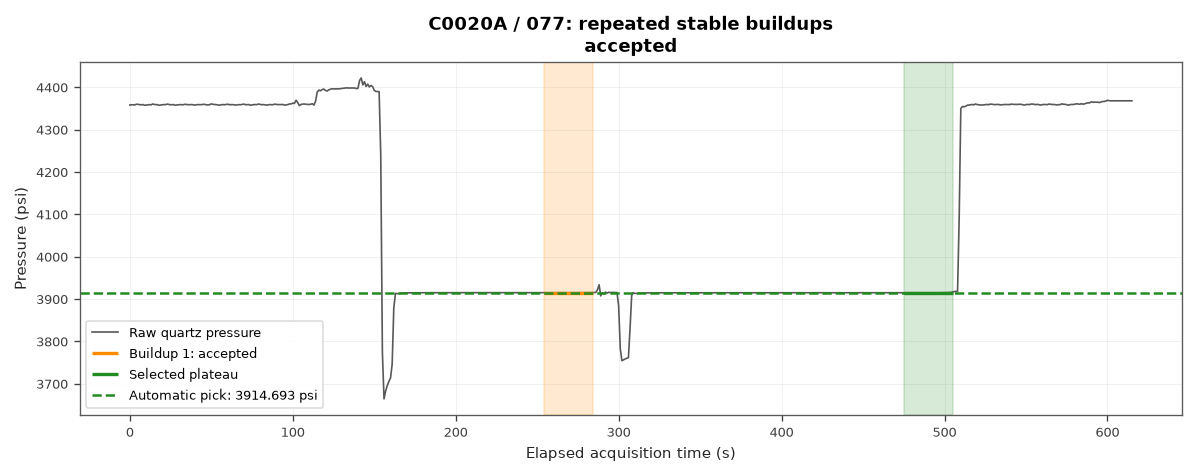

Review example: review usable pressure: None
QC flags: ('buildup_still_drifting', 'unstable_pressure_plateau', 'successive_tail_windows_disagree')


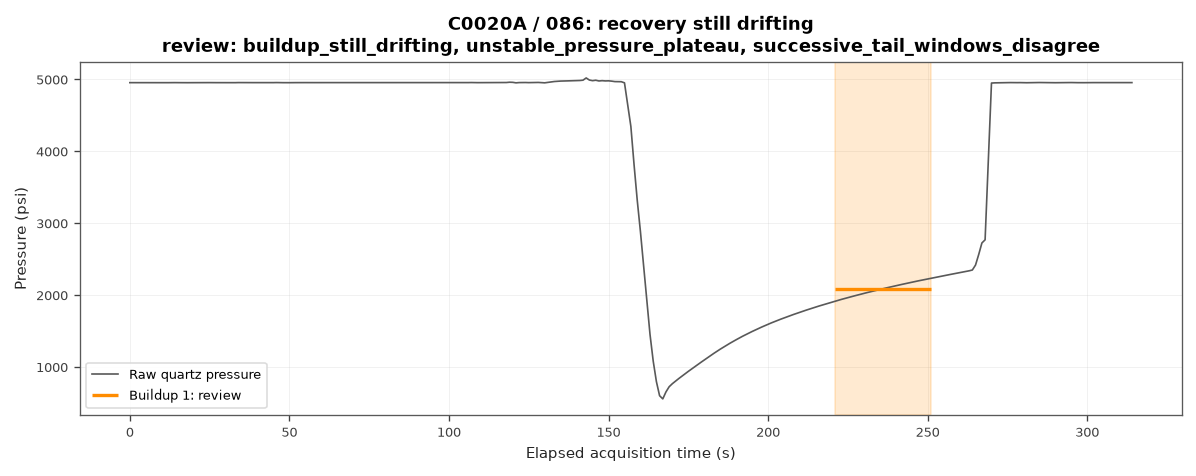

In [7]:
from petrophys.interpretation.saturation.height import (
    read_mdt_pretest, formation_pressures_from_mdt,
)
from petrophys.visualization import create_mdt_pretest_plot

raw_trace = read_mdt_pretest(pp.sample("c0020a_mdt_077"))
raw_pick = raw_trace.pick_pressure()
print("Pick:", raw_pick.status, round(raw_pick.pressure, 3), raw_pick.pressure_unit)
print("Probe depth:", raw_pick.station_depth, raw_pick.depth_unit, raw_pick.depth_reference)
print("Final recorded sample:", round(raw_trace.pressure[-1], 3), raw_trace.pressure_unit)
print("Buildup windows:", len(raw_pick.buildups), "Flags:", raw_pick.flags)
fig = create_mdt_pretest_plot(raw_trace, raw_pick, title="C0020A / 077: repeated stable buildups")
plt.show()

failed_trace = read_mdt_pretest(pp.sample("c0020a_mdt_086"))
failed_pick = failed_trace.pick_pressure()
print("Review example:", failed_pick.status, "usable pressure:", failed_pick.pressure)
print("QC flags:", failed_pick.flags)
assert failed_pick.pressure is None
fig = create_mdt_pretest_plot(failed_trace, failed_pick, title="C0020A / 086: recovery still drifting")
plt.show()

**External verification against the report.** Run all raw traces first, then
join the independent reference table using the original file ID. The reference
CSV uses each test page's *Formation Pressure*, leaving tight/lost-seal tests
null; *Last Read Buildup* is not substituted for a valid pressure. The report's
valid-test label is not itself a guarantee that a recovery meets our plateau
criteria. Neither these reference values nor their statuses enter the picker.


In [8]:
native_paths = sorted(pp.sample("c0020a_mdt_077").parent.glob("c0020a_mdt_*.las"))
raw_picks = [read_mdt_pretest(path).pick_pressure() for path in native_paths]
computed = pd.DataFrame([
    {"FILE": path.name, "status": pick.status, "picked_psi": pick.pressure,
     "flags": "; ".join(pick.flags)}
    for path, pick in zip(native_paths, raw_picks)
])
# The source report is consulted only after the raw-data computation above.
reference = pd.read_csv(pp.sample("c0020a_mdt_report_reference"))
verification = computed.merge(reference, on="FILE", validate="one_to_one")
verification["error_psi"] = verification.picked_psi - verification.REPORT_PRESSURE_PSI
print(verification.groupby(["REPORT_STATUS", "status"]).size().to_string())
accepted = verification.status.eq("accepted")
print("Maximum accepted difference:", round(verification.loc[accepted, "error_psi"].abs().max(), 3), "psi")
assert accepted.sum() == 22
assert verification.loc[accepted, "error_psi"].abs().max() < 0.2
assert verification.loc[verification.REPORT_STATUS.ne("Valid Test"), "picked_psi"].isna().all()
print("\nTests requiring review:")
print(verification.loc[~accepted, ["FILE_ID", "REPORT_STATUS", "flags"]].to_string(index=False))

REPORT_STATUS  status  
Lost Seal      review       2
Tight Test     review       2
Valid Test     accepted    22
               review       9
Maximum accepted difference: 0.149 psi

Tests requiring review:
 FILE_ID REPORT_STATUS                                                                                                          flags
      70    Valid Test                                                                                       repeat_pretests_disagree
      85    Valid Test                                                              buildup_still_drifting; unstable_pressure_plateau
      86    Tight Test                            buildup_still_drifting; unstable_pressure_plateau; successive_tail_windows_disagree
      87    Valid Test                            buildup_still_drifting; unstable_pressure_plateau; successive_tail_windows_disagree
      95    Valid Test                                                                                   no_sufficient_bui

The default picker accepts **22 of 35** traces; their largest difference from
published formation pressure is **0.149 psi**. It withholds both tight tests,
both lost seals, and nine report-valid traces because of residual drift,
repeat disagreement, insufficient windows or multiple mud returns. This is
verification on one field delivery, not a guarantee for unseen wells.

**Pass accepted picks to contact inference.** For your own reservoir, supply
one verified positive-down TVD per input trace and a shared datum. The bridge
normalizes pressure units, retains source/QC information, leaves review
pressures null and excludes them from fitting:

```python
stations = formation_pressures_from_mdt(
    picks, tvd=station_tvd_m, depth_unit="m", depth_reference="TVDSS",
)
contacts = stations.infer_contacts()
```

`station_tvd_m` must come from your survey or verified station metadata in the
same order as `picks`; MD is never silently used as TVD. Select a connected
reservoir and common pressure reference first. We do not infer an oil/water
contact across the entire C0020A borehole. The next examples demonstrate the
station/contact stage on two separate North Sea wells with known TVD metadata.


### 3c. Infer contacts from unlabeled formation-pressure stations

For 35/11-13 we have 29 original station tests from the final report's Table 3.7.4,
with formation pressure in bar and positive-down TVD below MSL in metres. The
bundled LAS is our numeric export of that table, not the native MDT acquisition.
Its fluid codes were added for the earlier labeled-fit example. **We remove those
labels and the old fluid-dependent fit mask here.** The new selection uses only
original measurement remarks (`ok`), admitting all 21 good stations including the
two shallow gas stations. The fit receives no report contact or fluid assignment.

`infer_contacts()` compares one, two and three contiguous robust pressure-gradient
models. Density follows $dP/dz=\rho g$. It screens possible gas/oil/water sequences
and checks whether adjacent lines meet consistently with the observed depth gap.
A single line, pressure discontinuity, weak gradient contrast or nonunique phase
interpretation does not yield a definite FWL. The default pressure error scale
is **0.05 bar equivalent**, a configurable analysis assumption, not MDT accuracy.
Default density ranges overlap and should be replaced by reservoir PVT bounds
when available. A best statistical fit does not prove hydraulic connectivity.

In [9]:
from petrophys.interpretation.saturation.height import read_formation_pressure
from petrophys.visualization import create_pressure_contact_plot
import lasio

source_stations = pd.read_csv(pp.sample("35_11_13_mdt_points"))
unlabeled = source_stations.drop(columns=["FLUID", "USE_FIT"])
unlabeled["USE_FIT"] = unlabeled["REMARKS"].eq("ok")  # measurement QC only
pressure_data = read_formation_pressure(unlabeled)
pressure_fit = pressure_data.infer_contacts()
print("Selected stations:", int(pressure_data.points.use_fit.sum()))
print("Interpretation status:", pressure_fit.status)
print("Candidate fluid sequences:", pressure_fit.fluid_sequences)
print("FWL:", None if pressure_fit.fwl_depth is None else round(pressure_fit.fwl_depth, 2), "m TVD MSL")
print(pd.DataFrame([{"branch": i+1, "points": b.line.n,
                     "density_g_cc": round(b.density_g_cc, 3),
                     "possible_fluids": "/".join(b.fluid_candidates)}
                    for i, b in enumerate(pressure_fit.branches)]).to_string(index=False))

# The same interpretation accepts unlabeled station LAS data.
station_las = lasio.read(pp.sample("35_11_13_mdt"))
station_las.delete_curve("FLUID")
del station_las.params["FLDMAP"]
station_las["USE_FIT"] = unlabeled["USE_FIT"].astype(int).to_numpy()
las_fit = read_formation_pressure(station_las).infer_contacts()
assert np.isclose(las_fit.fwl_depth, pressure_fit.fwl_depth)

Selected stations: 21
Interpretation status: interpreted
Candidate fluid sequences: (('oil', 'water'),)
FWL: 3113.17 m TVD MSL
 branch  points  density_g_cc possible_fluids
      1      12         0.655             oil
      2       9         0.982       oil/water


Difference from report: +0.57 m


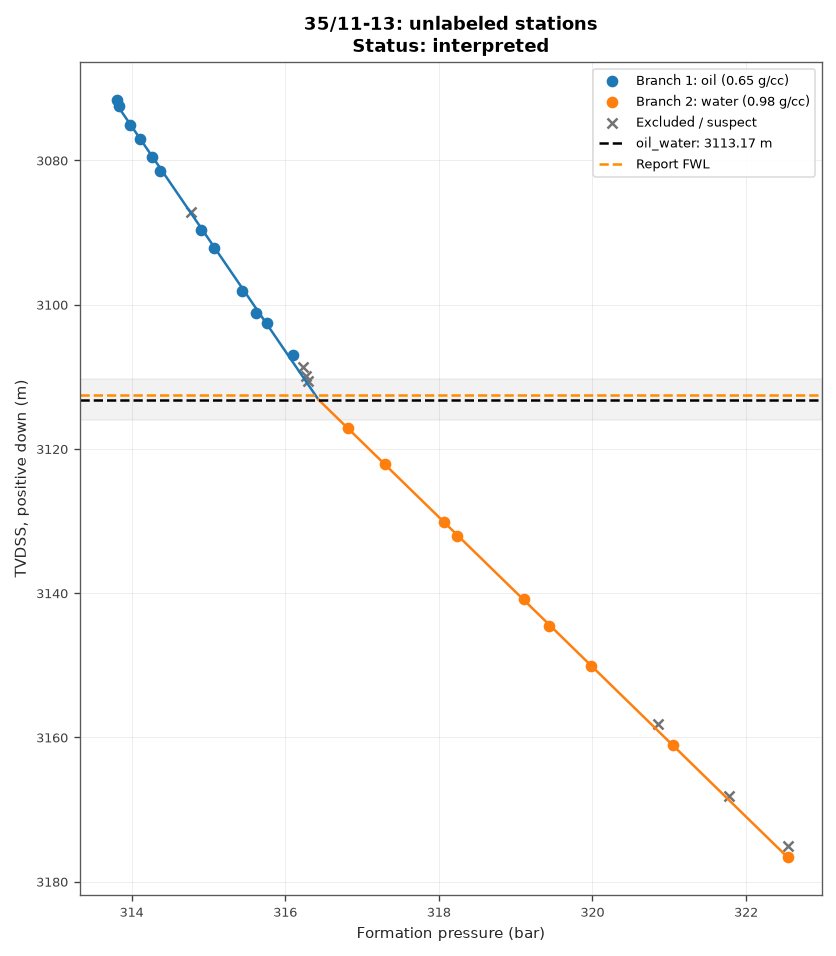

In [10]:
fig = create_pressure_contact_plot(pressure_data, pressure_fit, title="35/11-13: unlabeled stations")

# External verification only. The algorithm never receives this reported contact.
reported_fwl = 3112.6
assert pressure_fit.fwl_depth is not None
print(f"Difference from report: {pressure_fit.fwl_depth - reported_fwl:+.2f} m")
assert abs(pressure_fit.fwl_depth - reported_fwl) < 2.0
fig.axes[0].axhline(reported_fwl, color="darkorange", linestyle="--", label="Report FWL")
fig.axes[0].legend(fontsize=8)
plt.show()

The default interpretation gives an oil/water candidate at **3113.2 m TVD MSL**,
about **0.6 m deeper** than the report. No contact intervals or fluid labels were
passed into it. The selected two-gradient model groups 12 shallow and 9 deeper
stations; it does **not resolve the two-station gas leg separately**. This is an
example of the limits of sparse pressure measurements, not proof that every
station in the upper branch contains oil. Branch-count scores and density
hypotheses are available on the result for review.

Shaded plot intervals are conditional +/-2-sigma sensitivity to pressure error
and fitted line scatter. They exclude fluid-prior, segmentation, connectivity
and depth-datum uncertainty; they are not field-accuracy guarantees.

### Second well: return ambiguity instead of forcing a contact

The 35/11-10 Fensfjord example contains ten station markers digitized from
Figure 8.2 (PDF page 38) of its final report. Remove all labels here too. This
remains a preselected subset of visible markers with graph-resolution and
picking limitations, not the complete native MDT acquisition. The report's
**2290 m TVD MSL** contact is used only in the comparison after inference.

Status: ambiguous
Definite FWL: None
Possible fluid sequences: (('gas', 'oil'), ('gas', 'water'), ('oil', 'water'))
Candidate intersection: 2289.13 m TVD MSL; difference from report: -0.87 m


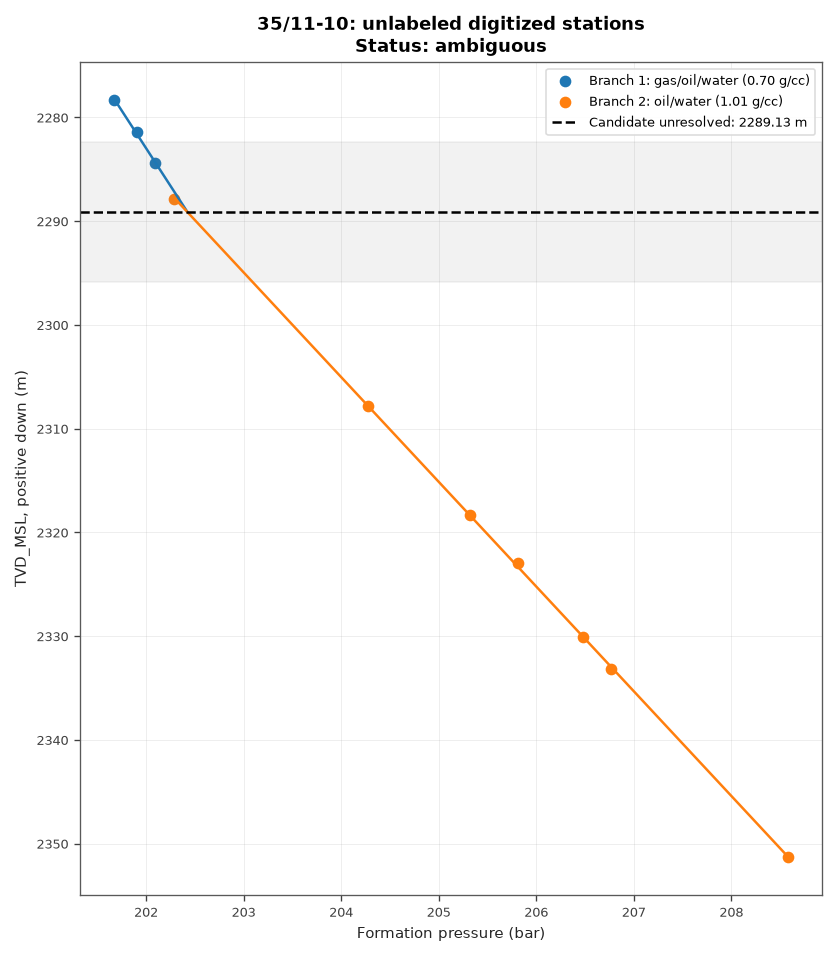

In [11]:
second_points = pd.read_csv(pp.sample("35_11_10_fensfjord_mdt_points"))
second_points = second_points.drop(columns=["FLUID", "USE_FIT"])
second_data = read_formation_pressure(second_points)
second_fit = second_data.infer_contacts()
print("Status:", second_fit.status)
print("Definite FWL:", second_fit.fwl_depth)
print("Possible fluid sequences:", second_fit.fluid_sequences)
for contact in second_fit.contacts:
    print(f"Candidate intersection: {contact.depth:.2f} m TVD MSL; "
          f"difference from report: {contact.depth - 2290:+.2f} m")
assert second_fit.status == "ambiguous" and second_fit.fwl_depth is None
fig = create_pressure_contact_plot(second_data, second_fit, title="35/11-10: unlabeled digitized stations")
plt.show()

The preferred two-branch intersection is approximately **2289.1 m**, but the
short upper branch leaves broad density possibilities at the assumed pressure
error. The method correctly exposes multiple phase sequences and leaves
`fwl_depth=None`. Changing `pressure_noise` changes model identifiability;
it must be grounded in measurement/picking quality, not tuned to a report contact.
Reservoir PVT density bounds can constrain `fluid_density_ranges` without
assigning individual stations. Independent samples/downhole fluid analysis and
geological connectivity provide stronger evidence than pressure alone.

For your own CSV or station LAS use `read_formation_pressure(path).infer_contacts()`.
`FLUID` is optional. Map custom depth/pressure columns and provide units and a
TVD datum if absent. A `USE_FIT` mask must express measurement QC, not known fluid
intervals. Existing labeled `.fit_fwl()` remains available for interpreted inputs.
Use the raw-pretest picker above before the station-gradient method when your
input is pressure versus acquisition time. Arbitrary hydraulic-compartment
discovery remains outside this method.

Pressure alone **cannot determine a saturation-height function**. Separate
capillary-pressure/rock calibration and fluid properties are required.

**The next section returns to HW-3.** Its unrelated assumed FWL in feet remains
separate from these metre-based pressure examples.

## 4. Predict Sw vs depth from logs and overlay

`saturation_height_from_logs` takes the fitted J-function, an FWL depth, and the
well's permeability/porosity curves, and returns a **predicted $S_w$ at every
depth**. Height above the FWL is `fwl_depth - depth`; below the FWL height is
clipped to zero -> $S_w = 1$.

One honesty note before reading the error statistic below: `SW_INPUT` is the
**same curve the J-function was fitted to**, so the mean absolute error is an
**in-sample goodness-of-fit check**, not independent prediction skill. Hold out
depths (or a whole well) from the fit for a real validation.

In [12]:
sw_pred = saturation_height_from_logs(
    well, model, fwl_depth=fwl_depth,
    perm_curve=('PERM_CC',), phi_curve=('PHIE_CC',),
    depth_increases_down=True,
)
print('predicted Sw: valid=%d  median=%.3f' % (np.isfinite(sw_pred).sum(),
                                               np.nanmedian(sw_pred)))

both = np.isfinite(sw_pred) & np.isfinite(sw_log)
resid = sw_pred[both] - sw_log[both]
print('vs log Sw: mean abs error = %.3f, bias = %+.3f'
      % (np.nanmean(np.abs(resid)), np.nanmean(resid)))

predicted Sw: valid=324  median=0.090
vs log Sw: mean abs error = 0.028, bias = -0.011


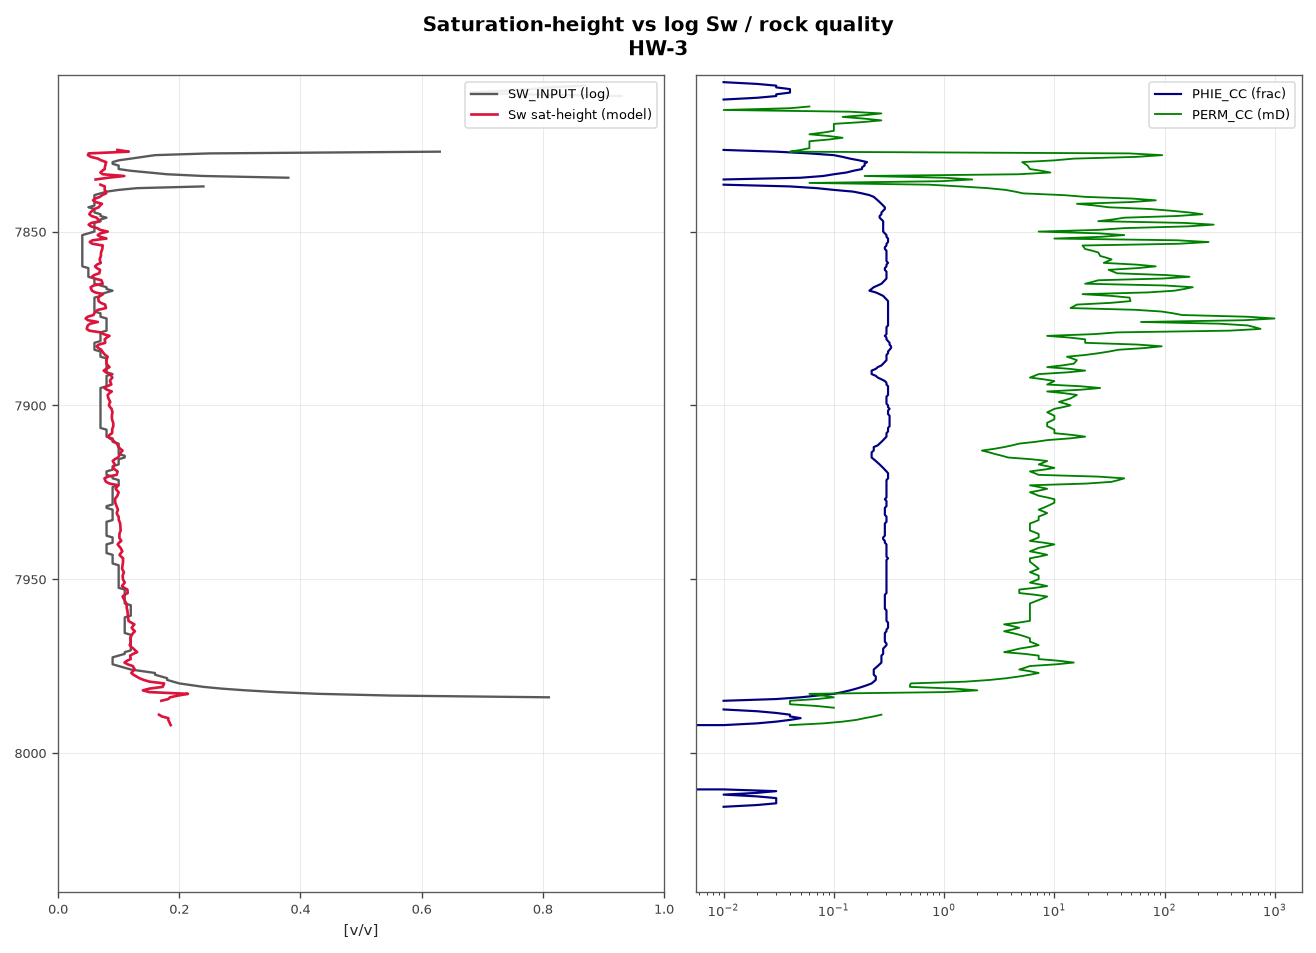

In [13]:
from petrophys.visualization import LogPlot

# Attach the predicted saturation-height Sw so a library plotter can render it.
well.add_curve('SW_SATHEIGHT', sw_pred, unit='v/v', description='Sw from sat-height model')

lp = LogPlot(well, figsize=(11, 8))
lp.create_figure(n_tracks=2)
# Track 0: log Sw vs saturation-height Sw
lp.add_curve(0, 'SW_INPUT', color='0.35', linewidth=1.4, xlim=(0, 1), label='SW_INPUT (log)')
lp.add_curve(0, 'SW_SATHEIGHT', color='crimson', linewidth=1.6, xlim=(0, 1),
             label='Sw sat-height (model)')
# Track 1: rock-quality context (porosity + log permeability)
lp.add_curve(1, 'PHIE_CC', color='navy', linewidth=1.3, label='PHIE_CC (frac)')
lp.add_curve(1, 'PERM_CC', color='green', linewidth=1.1, log_scale=True, label='PERM_CC (mD)')
lp.set_depth_range(top=well.start_depth, bottom=fwl_depth + 30)
lp.add_title('Saturation-height vs log Sw / rock quality')
lp.show()

Where the two $S_w$ curves diverge is diagnostic: if the saturation-height
model reads **drier** than the log $S_w$, either the FWL is picked too deep, the
rock-quality curves are off, or there is a genuine transition-zone /
low-resistivity-pay effect worth investigating.

## 5. The library's saturation-height diagnostic plot

`create_saturation_height_plot` renders the standard two-panel QC: the
**J-function fit** over the core points (left) and the resulting **Sw-vs-height
type curves** for a set of rock classes (right). This is the plot you would put
in a saturation-height report.

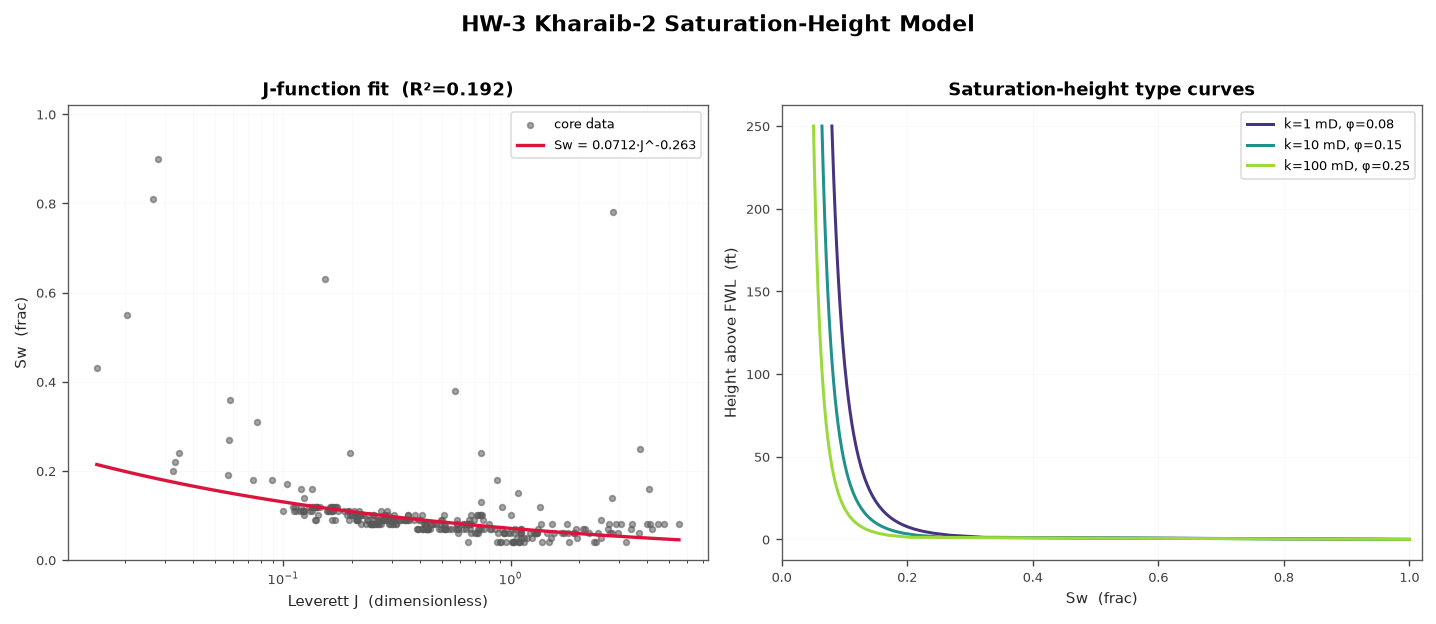

In [14]:
from petrophys.visualization import create_saturation_height_plot

fig = create_saturation_height_plot(
    model,
    j=J_core[fit_ok],
    sw=sw_log[fit_ok],
    rock_classes=[(1.0, 0.08), (10.0, 0.15), (100.0, 0.25)],
    max_height_ft=250.0,
    title='HW-3 Kharaib-2 Saturation-Height Model',
)
plt.show()

The right-hand type curves show the model's core prediction: at any given
height above the FWL, **better rock (higher $k$, higher $\phi$) holds less
water** - exactly the capillary physics we started with. These curves are what
get handed to the reservoir model to populate $S_w$ away from well control.

## Pitfalls & parameter choices

- **The FWL must come from data.** For HW-3 we *assumed* an FWL 20 ft below the
  deepest valid sample to make the demo self-contained; in practice pick it from formation
  pressures (RFT/MDT gradient intersection) or the deepest known water. A wrong
  FWL biases every predicted $S_w$.
- **J-function vs Brooks-Corey.** J-function normalises by $\sqrt{k/\phi}$, so **one**
  fit covers many rock qualities and is the model applied back to logs.
  Brooks-Corey describes a **single** drainage curve - fit it per rock type / per
  plug.
- **Always lab-to-reservoir convert Pc.** Never fit reservoir saturations to raw
  air-mercury Pc; use `convert_pc_lab_to_reservoir` first.
- **Units.** This module is field units throughout: Pc in psi, height in ft, $k$
  in mD, $\phi$ as a **fraction**, IFT in dyne/cm, angle in degrees.
- **Modest $R^2$ is normal** in heterogeneous carbonates; consider fitting
  separate J-functions per flow unit / rock type.

## Recap

- **Height above the FWL is a rescaled capillary pressure**:
  $P_c = 0.433(\mathrm{SG}_w-\mathrm{SG}_{hc})h$.
- The **Leverett J-function** normalises $P_c$ by $\sqrt{k/\phi}$ so different rock
  qualities collapse onto one curve.
- **Brooks-Corey** ($S_{wir}, P_d, \lambda$) describes a single drainage curve;
  the **J power-law** ($S_w = aJ^b$) is what we apply back to logs.
- Lab Pc must be **converted to reservoir** fluid conditions before use.
- `saturation_height_from_logs` turns a fitted model + FWL + $(k,\phi)$ curves
  into a predicted $S_w$ profile you can overlay on the resistivity-based
  $S_w$ (here an in-sample comparison, since the same curve trained the fit).
- The 35/11-13 MDT example fits FWL from oil/water pressure gradients and
  checks it against the source report, keeping TVD, units and QC explicit.


## Try it yourself

> **Exercise 1.** Move the assumed FWL up and down by +/-30 ft and re-run the
> prediction. How sensitive is the mean absolute error to the FWL pick?
>
> **Exercise 2.** Fit the J-function with `form='power_swir'` and an explicit
> `swir=0.1` floor. Does forcing an irreducible asymptote improve the deep,
> tight-rock predictions?
>
> **Exercise 3.** Using the fitted HW-3 Kharaib-2 J-function (`model`), compute the height
> above the FWL at which $S_w$ first falls below 0.5 for a 10 mD / 0.15 rock
> versus a 100 mD / 0.25 rock (hint: invert $S_w = a\,J^b$ for $J$, then
> `pc_from_j` and `height_from_pc`).

## What's next

Continue with **16 - Borehole Images and FMI**. Part B then runs through
lesson 20: 17 (visualization masterclass), 18 (multiwell field study), 19 (LLM
context generation) and 20 (Petrophys for LLM agents over MCP). Along the way,
revisit the Part A water-saturation lesson (07) and compare its Archie $S_w$
against this saturation-height prediction - reconciling the two is the heart
of a defensible reservoir saturation model.